In [3]:
%pip install numpy pandas seaborn matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
fmri = sns.load_dataset('fmri')
fmri.head()

,subject,timepoint,event,region,signal
0,s13,18,stim,parietal,-0.017552
1,s5,14,stim,parietal,-0.080883
2,s12,18,stim,parietal,-0.081033
3,s11,18,stim,parietal,-0.046134
4,s10,18,stim,parietal,-0.037970


In [5]:
type(fmri)

pandas.DataFrame

Text(0, 0.5, 'percent singal change')

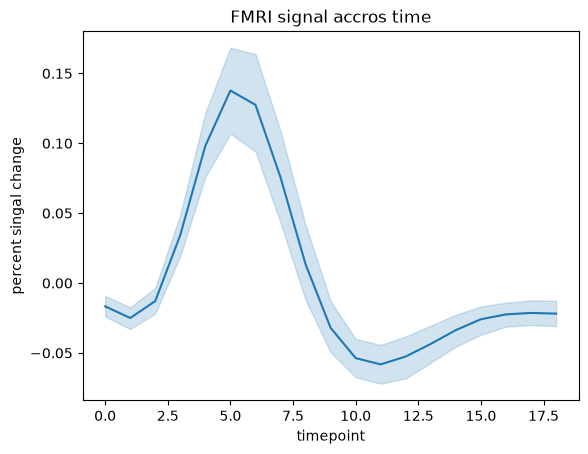

In [12]:
sns.lineplot(x="timepoint", y="signal", data=fmri)
plt.title("FMRI signal accros time")
plt.xlabel("timepoint")
plt.ylabel("percent singal change")

<Axes: xlabel='timepoint', ylabel='signal'>

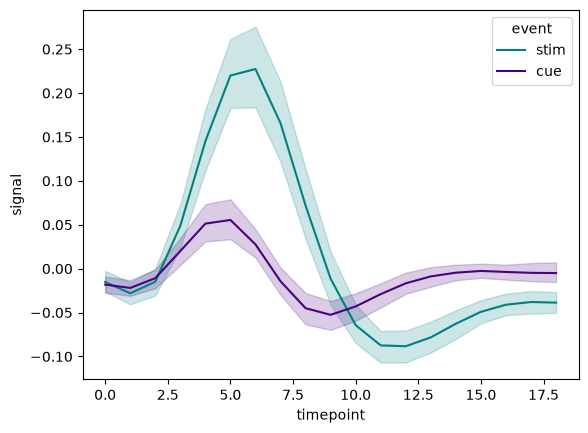

In [8]:
sns.lineplot(x="timepoint", y="signal", hue="event", palette=["teal", "indigo"], data=fmri)

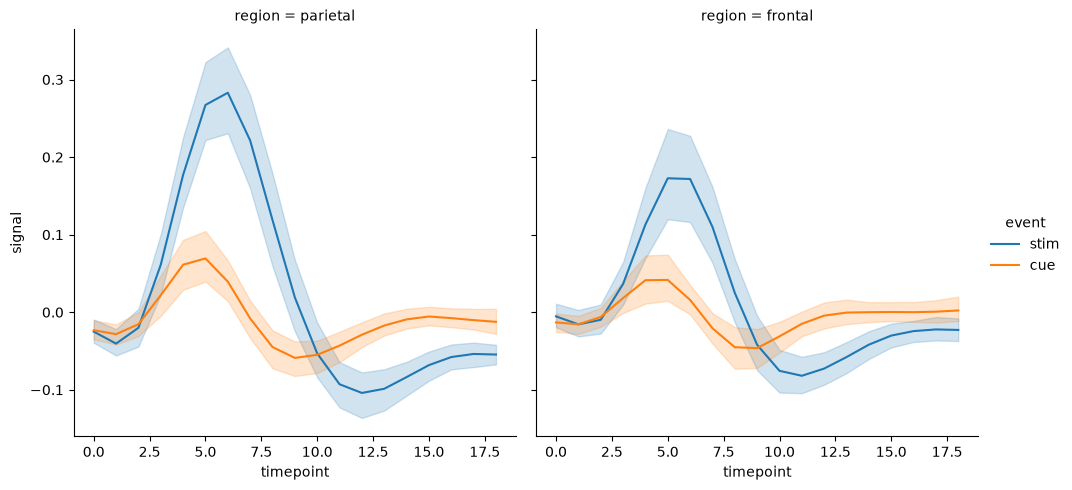

In [9]:
sns.relplot(
    x="timepoint",
    y="signal",
    col="region",
    hue="event",
    kind="line",
    data=fmri
)

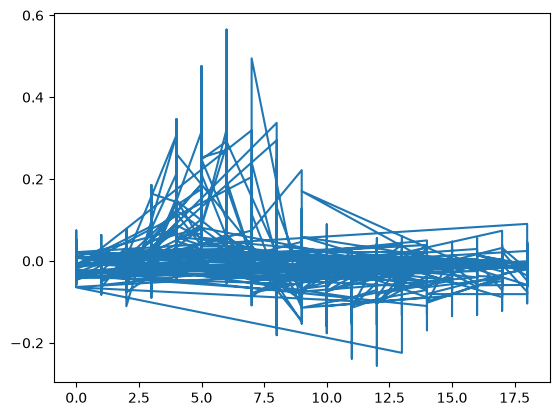

In [10]:
plt.plot(fmri["timepoint"], fmri["signal"])
plt.show()

In [11]:
fmri

,subject,timepoint,event,region,signal
0,s13,18,stim,parietal,-0.017552
1,s5,14,stim,parietal,-0.080883
2,s12,18,stim,parietal,-0.081033
3,s11,18,stim,parietal,-0.046134
4,s10,18,stim,parietal,-0.037970
...,...,...,...,...,...
1059,s0,8,cue,frontal,0.018165
1060,s13,7,cue,frontal,-0.029130
1061,s12,7,cue,frontal,-0.004939
1062,s11,7,cue,frontal,-0.025367


In [13]:
new_df = pd.DataFrame({
    "years": [2014, 2015, 2016, 2017, 2018, 2019, 2020],
    "sales": [4800, 4900, 5000, 5700, 5000, 6500, 6700]
})

new_df.head()

,years,sales
0,2014,4800
1,2015,4900
2,2016,5000
3,2017,5700
4,2018,5000


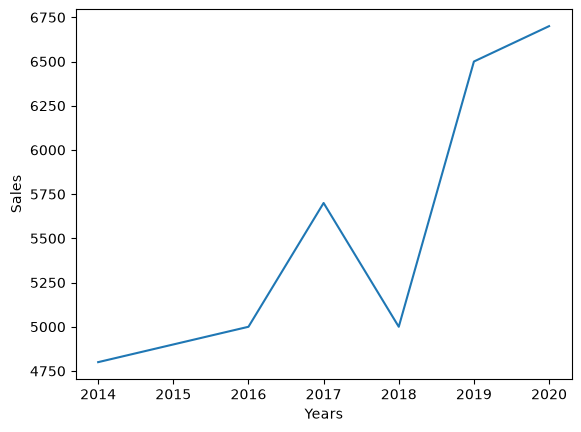

In [14]:
plt.plot(new_df["years"], new_df["sales"])
plt.xlabel("Years")
plt.ylabel("Sales")
plt.show()

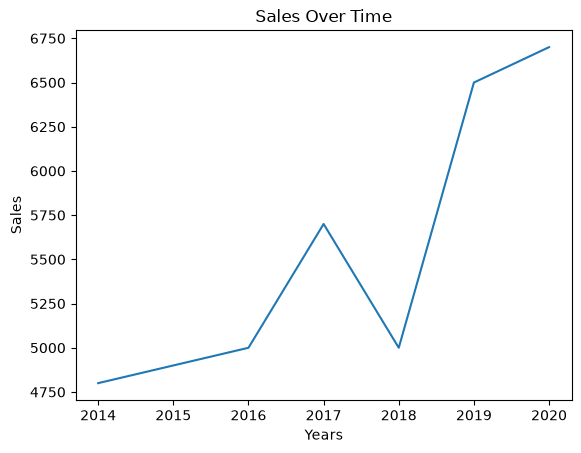

In [15]:
plt.plot(new_df["years"], new_df["sales"])
plt.title("Sales Over Time")
plt.xlabel("Years")
plt.ylabel("Sales")
plt.show()

In [16]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


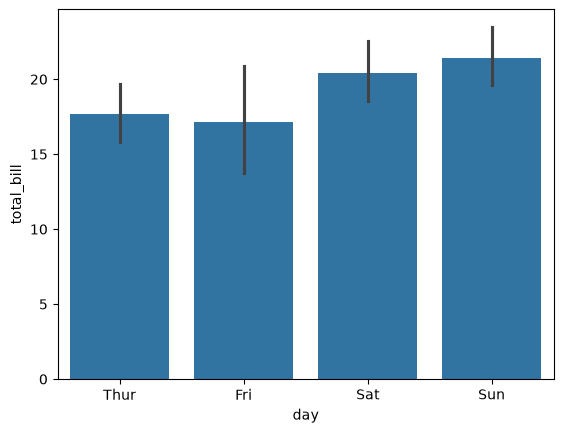

In [17]:
sns.barplot(x="day", y="total_bill", data=tips)
plt.show()

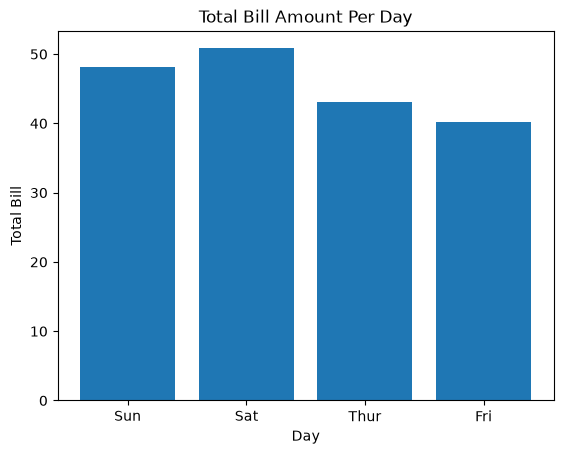

In [24]:
plt.bar(tips["day"], tips["total_bill"])

plt.title("Total Bill Amount Per Day")
plt.xlabel("Day")
plt.ylabel("Total Bill")

plt.show()

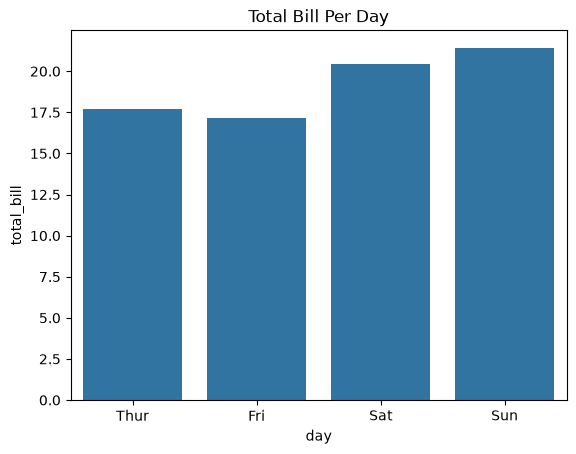

In [28]:
# seeborn 
sns.barplot(
    x="day",
    y="total_bill",
    data=tips,
    errorbar=None
)

plt.title("Total Bill Per Day")
plt.show()

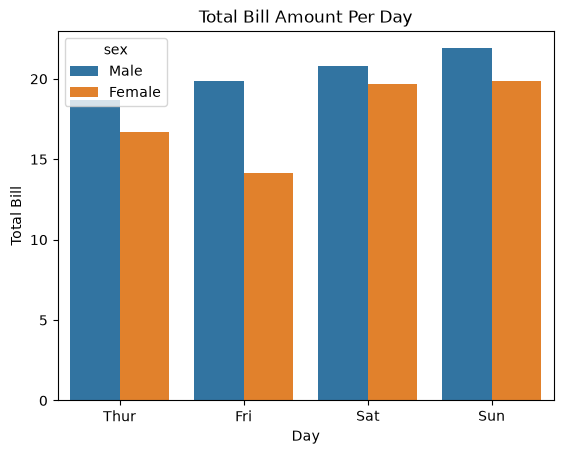

In [20]:
sns.barplot(x="day", y="total_bill", data=tips, hue="sex", errorbar=None)
plt.title("Total Bill Amount Per Day")
plt.xlabel("Day")
plt.ylabel("Total Bill")
plt.show()

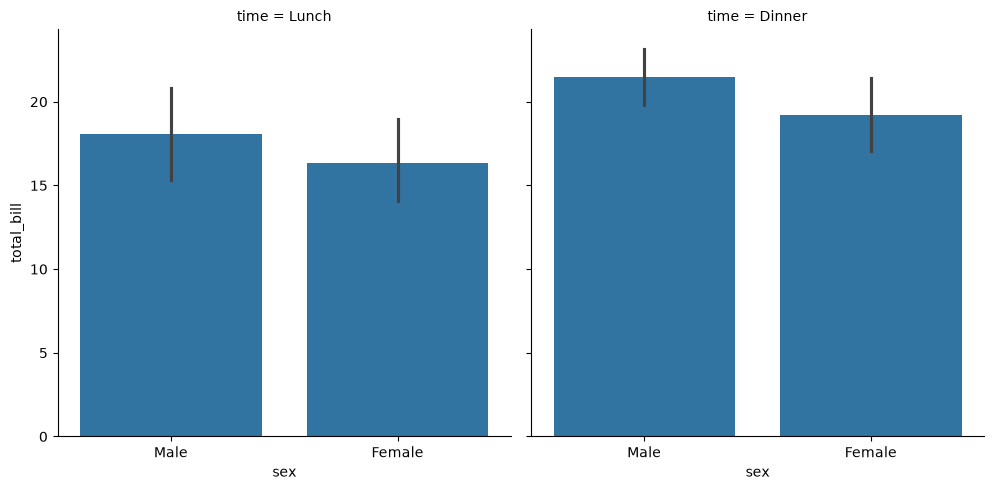

In [21]:
sns.catplot(
    x="sex",
    y="total_bill",
    col="time",
    data=tips,
    kind="bar"
)
plt.show()

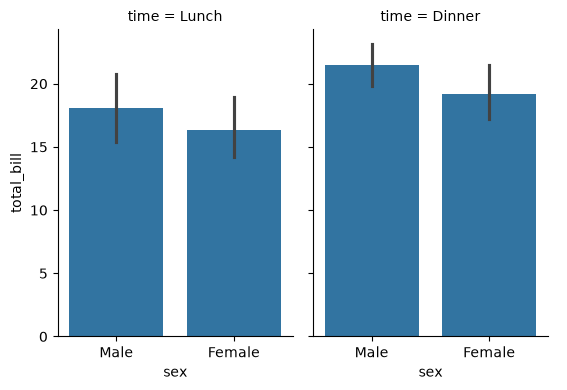

In [22]:
sns.catplot(
    x="sex",
    y="total_bill",
    col="time",
    data=tips,
    kind="bar",
    height=4,
    aspect=0.7
)
plt.show()

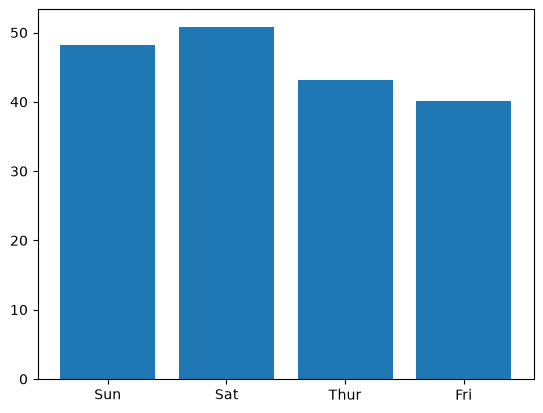

In [29]:
plt.bar(tips["day"], tips["total_bill"])
plt.show()

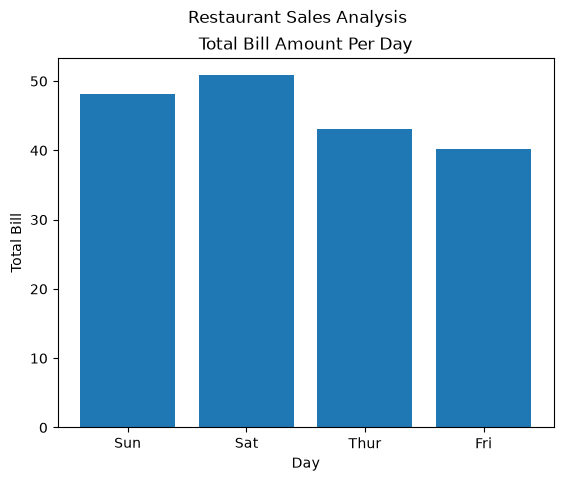

In [31]:
plt.bar(tips["day"], tips["total_bill"])
plt.title("Total Bill Amount Per Day")
plt.suptitle("Restaurant Sales Analysis")
plt.xlabel("Day")
plt.ylabel("Total Bill")
plt.show()

In [32]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [42]:
male = tips[tips["sex"] == "Male"]
female = tips[tips["sex"] == "Female"]

mday = male.groupby("day").mean(numeric_only=True)
fday = female.groupby("day").mean(numeric_only=True)

totals = mday.merge(
    fday,
    right_index=True,
    left_index=True,
    suffixes=("_male", "_female")
)

totals["total_tips"] = totals["tip_male"] + totals["tip_female"]

totals["prop_male"] = ( totals["tip_male"] / totals["total_tips"] * 100)

totals["prop_female"] = (totals["tip_female"] / totals["total_tips"] * 100)

totals

,total_bill_male,tip_male,size_male,total_bill_female,tip_female,size_female,total_tips,prop_male,prop_female
day,,,,,,,,,
Thur,18.714667,2.980333,2.433333,16.715312,2.575625,2.468750,5.555958,53.642111,46.357889
Fri,19.857000,2.693000,2.100000,14.145556,2.781111,2.111111,5.474111,49.195202,50.804798
Sat,20.802542,3.083898,2.644068,19.680357,2.801786,2.250000,5.885684,52.396600,47.603400
Sun,21.887241,3.220345,2.810345,19.872222,3.367222,2.944444,6.587567,48.885192,51.114808


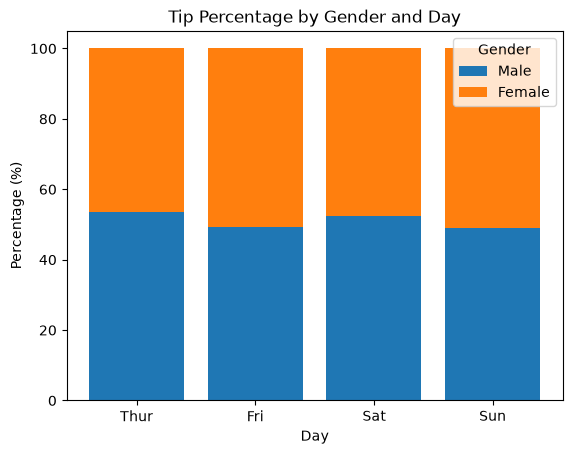

In [43]:
plt.bar(totals.index, totals["prop_male"], label="Male")
plt.bar(
    totals.index,
    totals["prop_female"],
    bottom=totals["prop_male"],
    label="Female"
)

plt.title("Tip Percentage by Gender and Day")
plt.xlabel("Day")
plt.ylabel("Percentage (%)")
plt.legend(title="Gender")
plt.show()

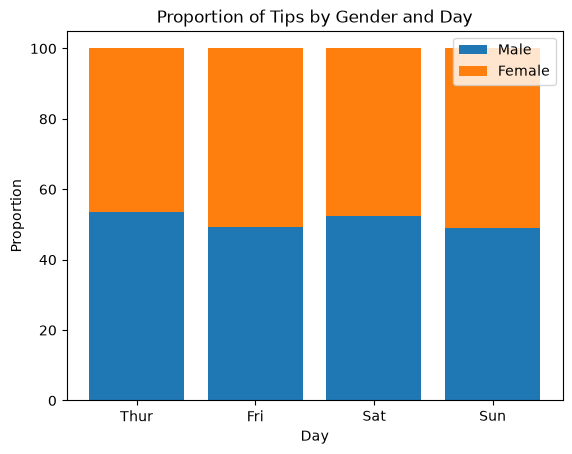

In [44]:
plt.bar(totals.index, totals["prop_male"], label="Male")
plt.bar(totals.index, totals["prop_female"], bottom=totals["prop_male"], label="Female")

plt.title("Proportion of Tips by Gender and Day")
plt.xlabel("Day")
plt.ylabel("Proportion")
plt.legend()
plt.show()

In [52]:
data = np.random.rand(1000)
data

array([5.79268575e-01, 8.33627655e-01, 7.31624760e-01, 5.43196368e-01,
       5.88408824e-02, 5.61890758e-02, 4.95797128e-01, 5.76383091e-01,
       8.46491578e-01, 9.80370023e-02, 3.50902900e-01, 7.21189879e-01,
       1.28568760e-01, 8.54769667e-01, 7.56413224e-01, 8.21279141e-01,
       4.05234524e-01, 5.19066515e-01, 4.15038892e-01, 1.28596890e-01,
       6.21277424e-01, 9.49646093e-01, 8.12342209e-01, 9.86044907e-02,
       3.46702873e-01, 2.27228238e-01, 1.41360469e-01, 4.22405101e-01,
       5.49858931e-01, 5.64644516e-01, 8.80725301e-01, 9.71536250e-01,
       7.58254061e-01, 3.42666664e-01, 4.91041925e-01, 5.28252914e-01,
       7.46002632e-01, 4.26057319e-03, 9.01581905e-03, 4.39062288e-01,
       7.27541729e-01, 2.32184769e-01, 7.40849510e-01, 6.49541622e-02,
       2.69782918e-01, 2.84814388e-01, 7.54530153e-02, 2.32626922e-01,
       9.07827097e-01, 5.83784625e-01, 9.74177868e-01, 4.73782611e-01,
       5.06843304e-01, 7.53247628e-01, 9.33494625e-01, 2.78740252e-01,
      

(array([108., 105.,  94.,  97., 105.,  92., 108.,  99.,  93.,  99.]),
 array([0.00104111, 0.10070764, 0.20037418, 0.30004072, 0.39970726,
        0.4993738 , 0.59904034, 0.69870688, 0.79837342, 0.89803996,
        0.9977065 ]),
 <BarContainer object of 10 artists>)

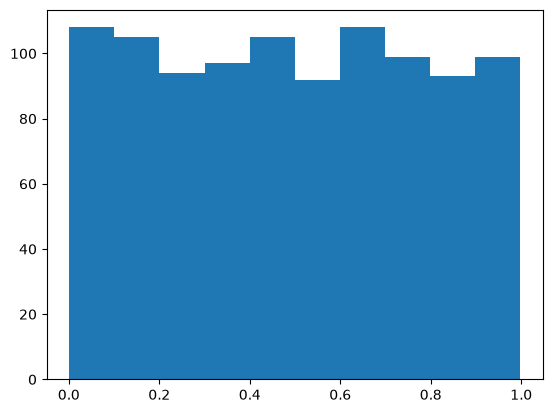

In [50]:
plt.hist(data)

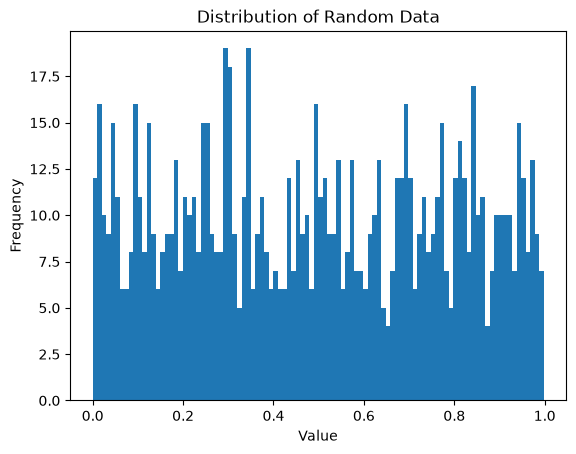

In [55]:
plt.hist(data, bins=100)
plt.title("Distribution of Random Data")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

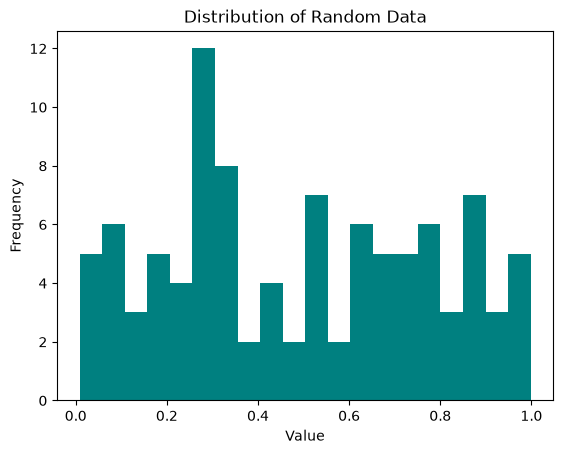

In [56]:
data2 = np.random.rand(100)

plt.hist(data2, bins=20, color="teal")
plt.title("Distribution of Random Data")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

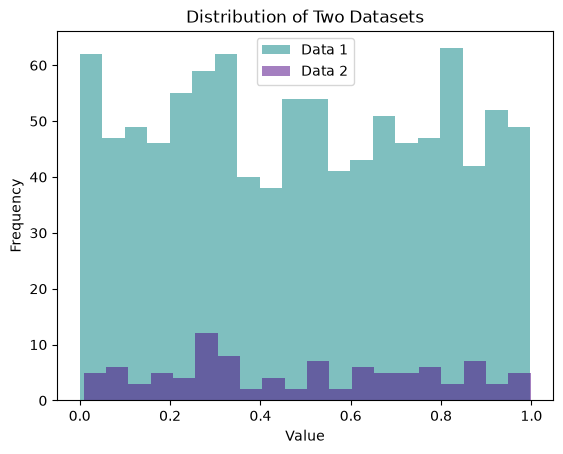

In [59]:
plt.hist(data, bins=20, color="teal", alpha=0.5, label="Data 1") 
plt.hist(data2, bins=20, color="indigo", alpha=0.5, label="Data 2")

plt.title("Distribution of Two Datasets")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

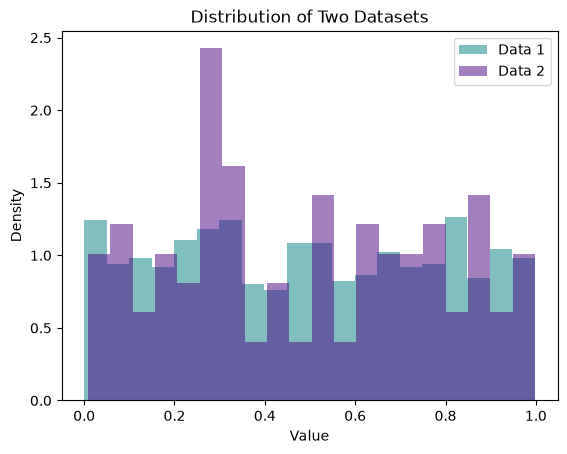

In [60]:
plt.hist(data, bins=20, color="teal", alpha=0.5, label="Data 1", density=True)
plt.hist(data2, bins=20, color="indigo", alpha=0.5, label="Data 2", density=True)

plt.title("Distribution of Two Datasets")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()

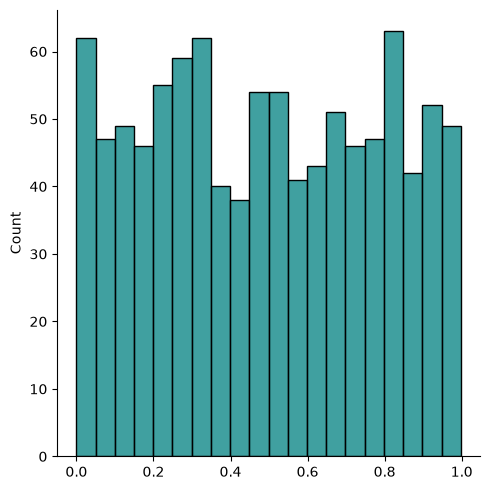

In [61]:
sns.displot(data, bins=20, color="teal")
plt.show()

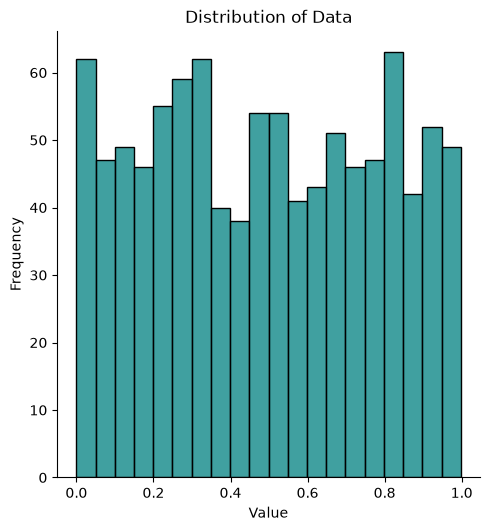

In [62]:
sns.displot(data, bins=20, color="teal")
plt.title("Distribution of Data")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

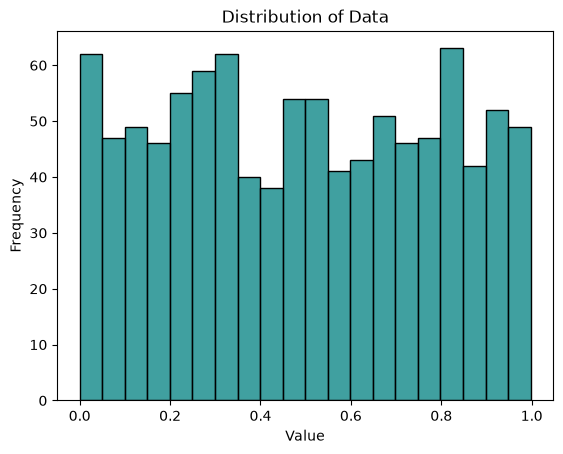

In [63]:
sns.histplot(data, bins=20, color="teal")

plt.title("Distribution of Data")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

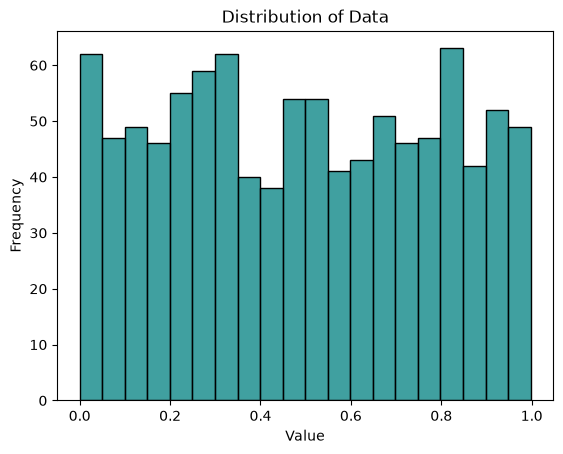

In [67]:
sns.histplot(data, bins=20, color="teal")

plt.title("Distribution of Data")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

In [69]:
iris = sns.load_dataset("iris")
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


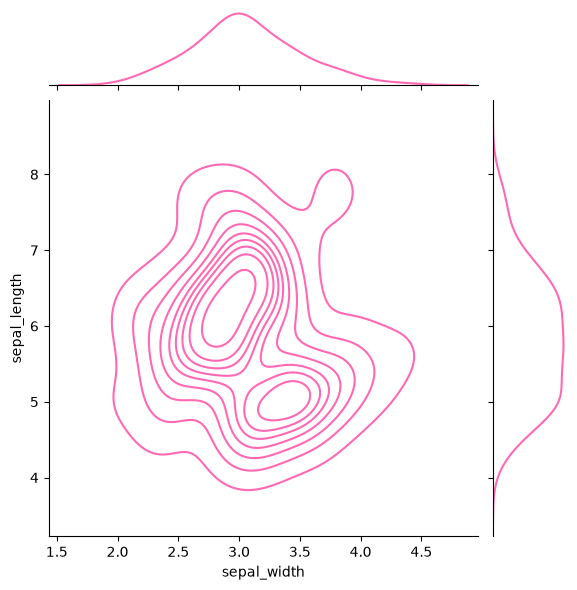

In [70]:
sns.jointplot(
    x="sepal_width",
    y="sepal_length",
    data=iris,
    color="hotpink",
    kind="kde"
)
plt.show()

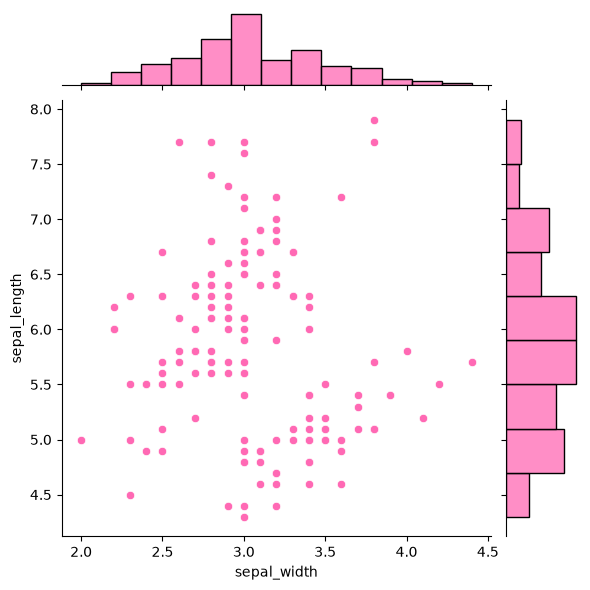

In [71]:
sns.jointplot(
    x="sepal_width",
    y="sepal_length",
    data=iris,
    color="hotpink",
    kind="scatter"
)
plt.show()

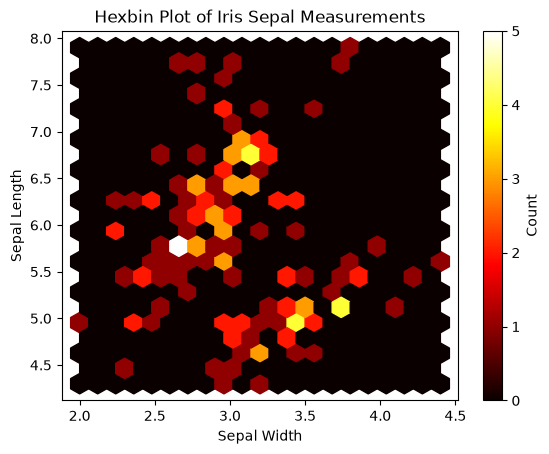

In [72]:
plt.hexbin(
    iris["sepal_width"],
    iris["sepal_length"],
    gridsize=20,
    cmap="hot"
)

plt.title("Hexbin Plot of Iris Sepal Measurements")
plt.xlabel("Sepal Width")
plt.ylabel("Sepal Length")
plt.colorbar(label="Count")
plt.show()

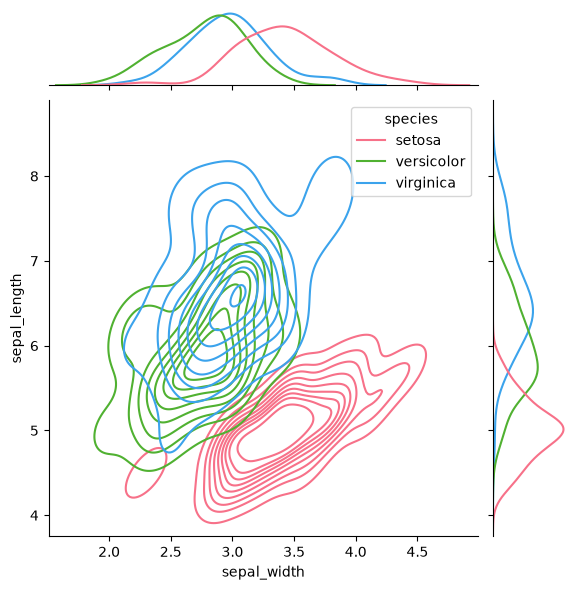

In [73]:
sns.jointplot(
    x="sepal_width",
    y="sepal_length",
    data=iris,
    hue="species",
    kind="kde",
    palette="husl"
)

plt.show()

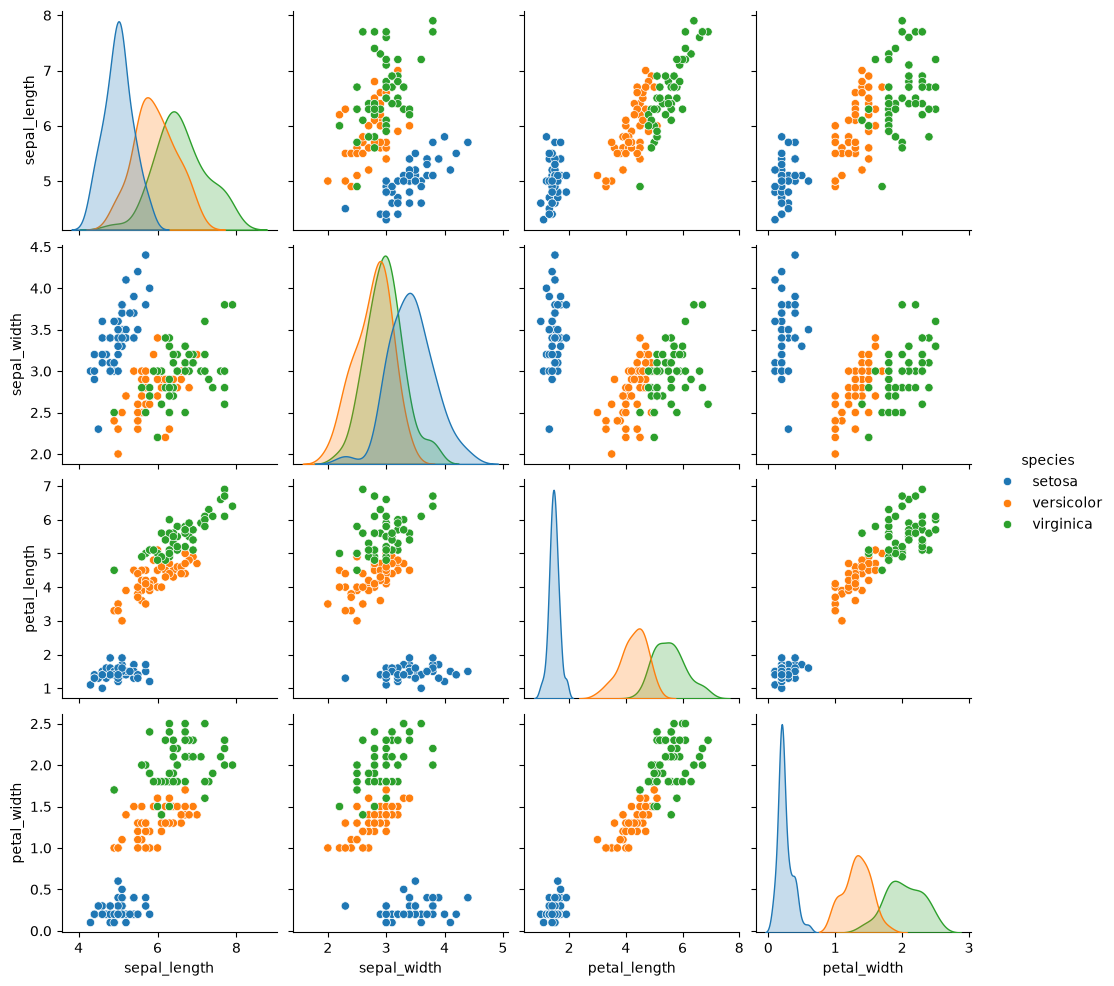

In [74]:
sns.pairplot(data=iris, hue="species")
plt.show()

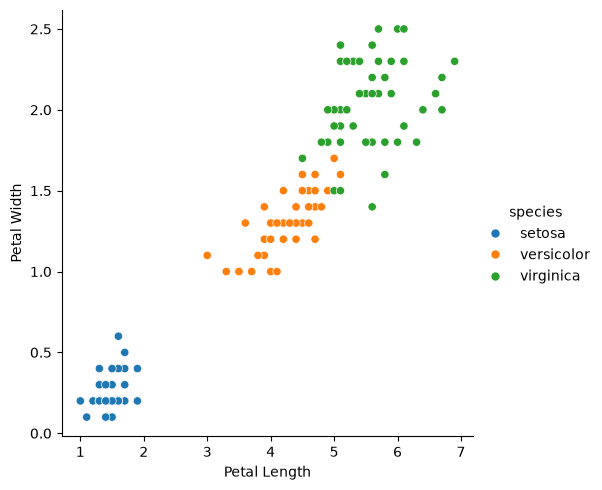

In [75]:
sns.relplot(
    data=iris,
    x="petal_length",
    y="petal_width",
    hue="species",
    kind="scatter"
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.show()

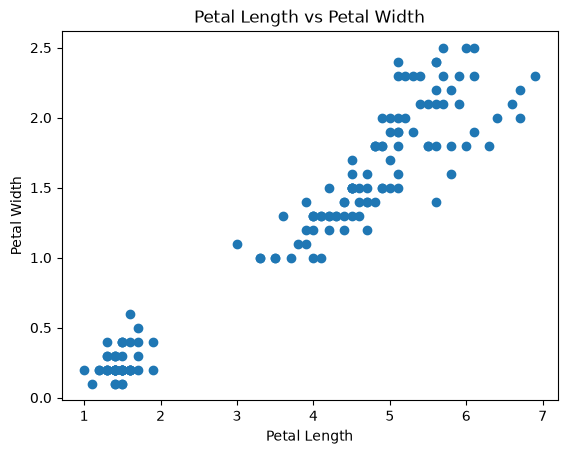

In [76]:
plt.scatter(iris["petal_length"], iris["petal_width"])

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.show()

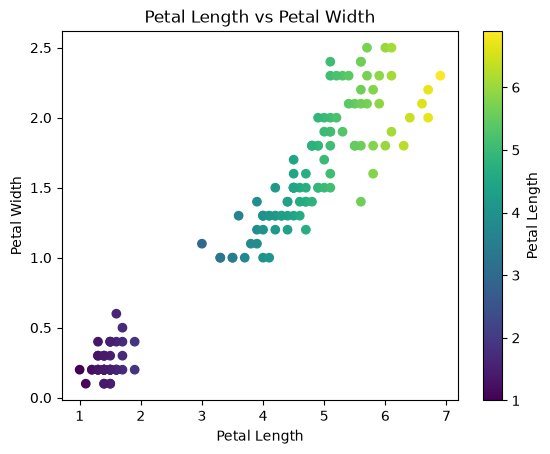

In [77]:
plt.scatter(
    iris["petal_length"],
    iris["petal_width"],
    c=iris["petal_length"],
    cmap="viridis"
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.colorbar(label="Petal Length")
plt.show()

In [78]:
flights = sns.load_dataset("flights")
flights.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [5]:
flights_pivot = flights.pivot(
    index="year",
    columns="month",
    values="passengers"
)

flights_pivot

NameError: name 'flights' is not defined

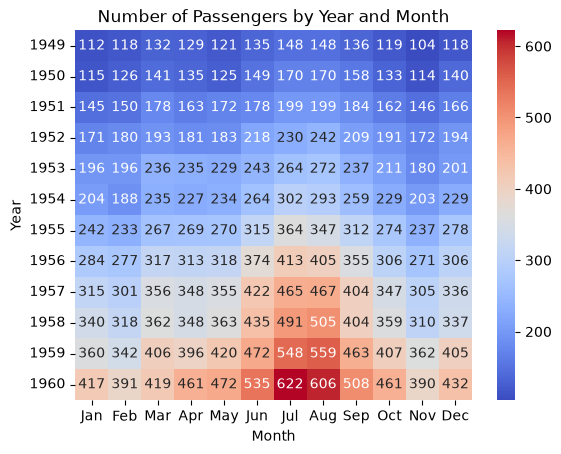

In [80]:
sns.heatmap(flights_pivot, cmap="coolwarm", annot=True, fmt="d")

plt.title("Number of Passengers by Year and Month")
plt.xlabel("Month")
plt.ylabel("Year")
plt.show()

In [81]:
%pip install scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 10.0 MB/s  0:00:02m0:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [82]:
import scipy

In [83]:
print(scipy.__version__)

1.18.1


In [84]:
%pip install scipy scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 5.3 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import scipy
import sklearn

print(scipy.__version__)
print(sklearn.__version__)

1.18.1
1.9.1


In [6]:
titanic = sns.load_dataset("titanic")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [7]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [8]:
titanic.groupby("class").mean(numeric_only=True)

,survived,pclass,age,sibsp,parch,fare,adult_male,alone
class,,,,,,,,
First,0.629630,1.0,38.233441,0.416667,0.356481,84.154687,0.550926,0.504630
Second,0.472826,2.0,29.877630,0.402174,0.380435,20.662183,0.538043,0.565217
Third,0.242363,3.0,25.140620,0.615071,0.393075,13.675550,0.649695,0.659878


In [9]:
titanic.groupby("class").size()

class
First     216
Second    184
Third     491
dtype: int64

In [11]:
%pip install squarify

Note: you may need to restart the kernel to use updated packages.


In [12]:
import squarify
import matplotlib.pyplot as plt

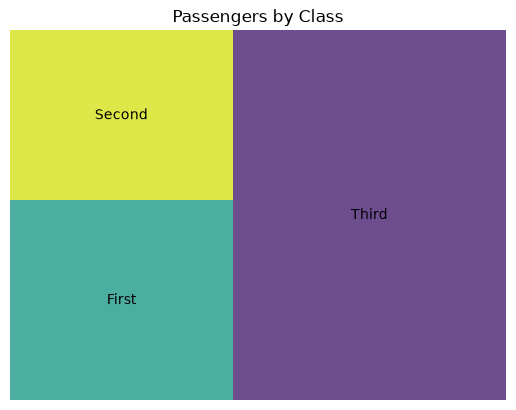

In [13]:
sizes = titanic.groupby("class", observed=True).size()

squarify.plot(
    sizes=sizes.values,
    label=sizes.index.astype(str),
    alpha=0.8
)

plt.title("Passengers by Class")
plt.axis("off")
plt.show()

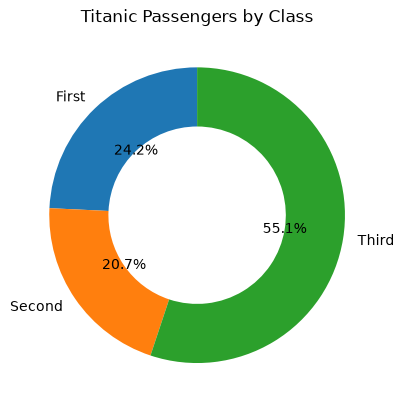

In [14]:
sizes = titanic.groupby("class", observed=True).size()

plt.pie(
    sizes,
    labels=sizes.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Titanic Passengers by Class")
plt.show()

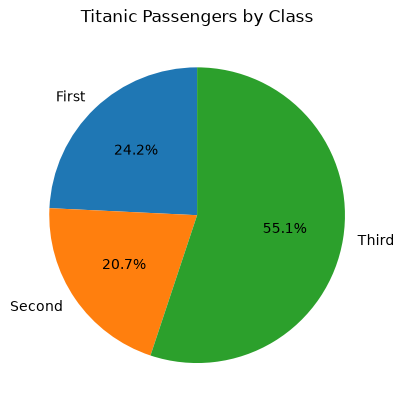

In [15]:
sizes = titanic.groupby("class", observed=True).size()

plt.pie(
    sizes,
    labels=sizes.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Titanic Passengers by Class")
plt.show()

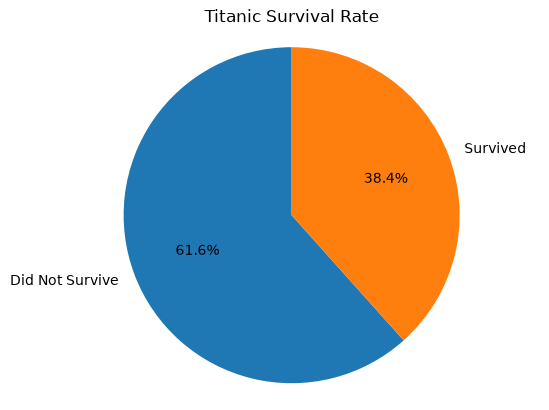

In [16]:
survived = titanic["survived"].value_counts().sort_index()

plt.pie(
    survived,
    labels=["Did Not Survive", "Survived"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Titanic Survival Rate")
plt.axis("equal")
plt.show()

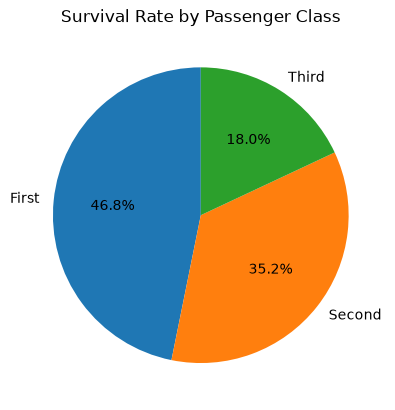

In [17]:
survival = titanic.groupby("class", observed=True)["survived"].mean() * 100

plt.pie(
    survival,
    labels=survival.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Survival Rate by Passenger Class")
plt.show()